# MLP Neural Network with PCA
**Dataset:** UCI Optdigits

This notebook compares tuned MLP pipelines on MinMax-scaled pixels and scaled pixels reduced by PCA, using five-fold stratified CV and one untouched official test evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/processed/optdigits_train_processed.csv", header=None, names=cols)
test  = pd.read_csv("../../data/processed/optdigits_test_processed.csv", header=None, names=cols)

print("Train shape:", train.shape)   # run this code to obtain actual value
print("Test shape:", test.shape)     # run this code to obtain actual value
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [3]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(train.iloc[:, :64])  # fit on train only

# --- Fit PCA on train only ---
pca_full = PCA().fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
print("Components needed for 95% variance:", n_components_95)  # run this code to obtain actual value


Components needed for 95% variance: 30


In [3]:
# --- Refit PCA with chosen n_components ---
pca = PCA(n_components=n_components_95)
X_train_pca = pca.fit_transform(X_train_scaled)
print("Reduced shape:", X_train_pca.shape)  # run this code to obtain actual value


Reduced shape: (3823, 30)


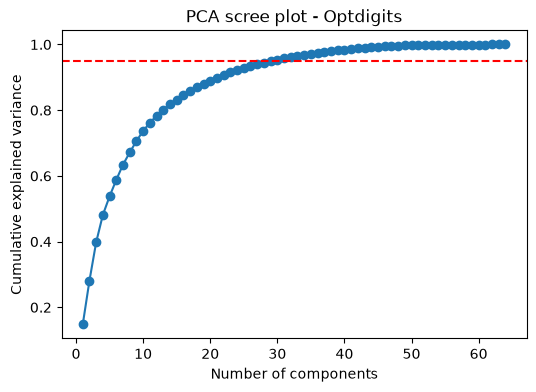

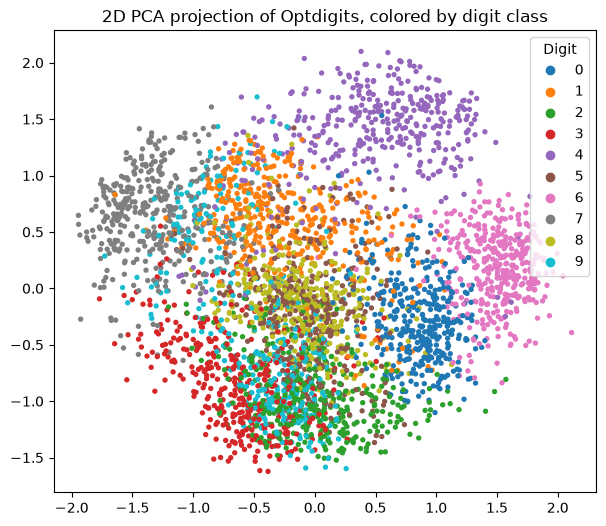

In [ ]:
# --- EDA visualization 1: scree plot ---
plt.figure(figsize=(6,4))
plt.plot(range(1, len(cum_var)+1), cum_var, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA scree plot - Optdigits")
plt.savefig("../../results/eda_visualizations/member5_pca_scree.png", dpi=150, bbox_inches="tight")
plt.show()

# --- EDA visualization 2: 2D PCA scatter colored by class ---
pca_2d = PCA(n_components=2).fit_transform(X_train_scaled)
plt.figure(figsize=(7,6))
scatter = plt.scatter(pca_2d[:,0], pca_2d[:,1], c=train["target"], cmap="tab10", s=8)
plt.legend(*scatter.legend_elements(), title="Digit")
plt.title("2D PCA projection of Optdigits, colored by digit class")
plt.savefig("../../results/eda_visualizations/member5_pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

An MLPClassifier is a nonlinear neural-network classifier for the ten digit classes. This experiment compares MinMax-scaled pixels with MinMax scaling followed by PCA retaining 95% variance. Scaling and PCA are inside each pipeline and refitted within every CV fold. `GridSearchCV` tunes hidden-layer size and L2 regularization with five-fold stratified CV; selection uses macro F1. The official test split is used only after selection for accuracy, macro precision/recall/F1, a classification report, and a confusion matrix.

,Model variant,CV accuracy,CV macro F1,Test accuracy,Test precision (macro),Test recall (macro),Test macro F1,Best parameters
0,MLP - scaled + PCA 95%,0.972534,0.972587,0.957707,0.959144,0.957619,0.957887,"{'classifier__alpha': 0.0001, 'classifier__hid..."
1,MLP - scaled pixels,0.966257,0.966299,0.948804,0.950154,0.948680,0.948884,"{'classifier__alpha': 0.0001, 'classifier__hid..."


CV-selected model: MLP - scaled + PCA 95%
Classification report on the held-out official test split:
              precision    recall  f1-score   support

           0     0.9944    0.9888    0.9915       178
           1     0.9351    0.9505    0.9428       182
           2     0.9831    0.9887    0.9859       177
           3     0.9942    0.9344    0.9634       183
           4     0.9672    0.9779    0.9725       181
           5     0.9365    0.9725    0.9542       182
           6     1.0000    0.9724    0.9860       181
           7     0.9821    0.9218    0.9510       179
           8     0.9294    0.9080    0.9186       174
           9     0.8693    0.9611    0.9129       180

    accuracy                         0.9577      1797
   macro avg     0.9591    0.9576    0.9579      1797
weighted avg     0.9592    0.9577    0.9579      1797



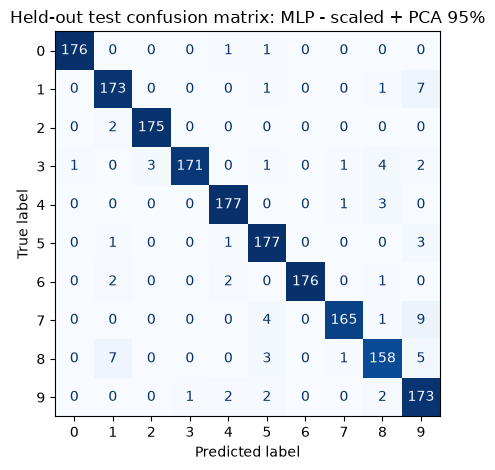

In [3]:
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

feature_cols = [f"pixel_{index}" for index in range(64)]
X_train = train[feature_cols]
y_train = train["target"].astype(int)
X_test = test[feature_cols]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
parameter_grid = {
    "classifier__hidden_layer_sizes": [(64,), (64, 32)],
    "classifier__alpha": [0.0001, 0.01],
}
experiments = {
    "MLP - scaled pixels": Pipeline([
        ("scaler", MinMaxScaler()),
        ("classifier", MLPClassifier(max_iter=500, early_stopping=True, random_state=42)),
    ]),
    "MLP - scaled + PCA 95%": Pipeline([
        ("scaler", MinMaxScaler()),
        ("pca", PCA(n_components=0.95)),
        ("classifier", MLPClassifier(max_iter=500, early_stopping=True, random_state=42)),
    ]),
}
results = []
best_models = {}
for variant_name, pipeline in experiments.items():
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best_models[variant_name] = search.best_estimator_
    predictions = search.predict(X_test)
    results.append({
        "Model variant": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision (macro)": precision_score(y_test, predictions, average="macro"),
        "Test recall (macro)": recall_score(y_test, predictions, average="macro"),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

pca_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(pca_model_comparison)

best_variant = pca_model_comparison.loc[0, "Model variant"]
best_predictions = best_models[best_variant].predict(X_test)
print(f"CV-selected model: {best_variant}")
print("Classification report on the held-out official test split:")
print(classification_report(y_test, best_predictions, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, cmap="Blues", colorbar=False)
plt.title(f"Held-out test confusion matrix: {best_variant}")
plt.tight_layout()
plt.show()

### Results and viva

PCA retaining 95% variance produced the strongest MLP result in this comparison: CV accuracy 97.25%, CV macro F1 97.26%, test accuracy 95.77%, and test macro F1 95.79%. The scaled-pixel MLP reached 96.63% CV macro F1 and 94.89% test macro F1. The result suggests PCA helped this MLP configuration, though the comparison uses one fixed official test split. Limitations include the small architecture/regularization grid, MLP training variability despite a fixed random seed, and no repeated or nested CV. The five-fold standard deviation was not recorded.